# Sampling the LJ13 Cluster with Parallel Tempering

The **LJ13** distribution is a Boltzmann distribution over 13 particles in 3D,
interacting through a Lennard-Jones 12-6 pair potential plus a harmonic trap
around the center of mass:

$$
p(x) \propto \exp\bigl(-\beta\, U(x)\bigr), \qquad
U(x) = \underbrace{2\sum_{i<j} \varepsilon \left[\left(\frac{r_m}{r_{ij}}\right)^{12}
- 2\left(\frac{r_m}{r_{ij}}\right)^6\right]}_{\text{LJ pair potential}}
+ \underbrace{\frac{s}{2} \sum_{i=1}^{13} \|x_i - \bar{x}\|^2}_{\text{harmonic trap}}
$$

where $r_{ij} = \|x_i - x_j\|$ is the Euclidean distance between particles $i$ and $j$
and $\bar{x} = \frac{1}{13}\sum_i x_i$ is the center of mass (COM).
Each pair interaction has minimum $-\varepsilon$ at distance $r = r_m$.
The $r^{-12}$ term is short-range repulsion; the $-2r^{-6}$ term is long-range attraction.
The harmonic trap (strength $s = 1$) penalizes the spread of particles around the COM.

**Note on the factor of 2 in the LJ term.** The standard physics convention sums
unique pairs ($i < j$, giving 78 terms for 13 particles). The
[DEM](https://github.com/jarridrb/DEM) and
[adjoint samplers](https://github.com/facebookresearch/adjoint_samplers)
implementations use bgflow's `distances_from_vectors`, which returns all
$N(N-1) = 156$ ordered pairs (both $(i,j)$ and $(j,i)$), effectively
double-counting each pair. With `energy_factor=1.0` (the default in both repos),
their LJ energy equals $2 \times \sum_{i<j}$. We include this factor to match
the reference samples from DEM (`data/test_split_LJ13-1000.npy`).

LJ13 has $\binom{13}{2} = 78$ interacting pairs. The global energy minimum
is the icosahedral configuration at $U_{\text{LJ}} \approx -44.33$ in the standard
convention ($\approx -88.66$ with the factor of 2),
but the landscape contains hundreds of local minima separated by high barriers.
This makes LJ13 a standard benchmark for sampling methods.

Since the pair potential depends only on pairwise distances, $U_{\text{LJ}}$ is invariant
under translations. The harmonic trap breaks this invariance, but it penalizes only the
internal spread, not the COM position. We handle the remaining translational invariance
by constraining COM=0 via a null-space projection, reducing the state space from
$\mathbb{R}^{39}$ to $\mathbb{R}^{36}$ (see below). On the COM=0 subspace, the trap
simplifies to $\frac{s}{2}\sum_i \|x_i\|^2$.

The LJ density is provided by the
[jax-pdf](https://github.com/alexxthiery/jax-pdf) package:

```bash
pip install -e git+https://github.com/alexxthiery/jax-pdf.git#egg=jax-pdf
```

In [1]:
from jax import config
config.update("jax_enable_x64", True)

import sys
from pathlib import Path

parent = Path().resolve().parent
if str(parent) not in sys.path:
    sys.path.insert(0, str(parent))

In [2]:
import jax
import jax.numpy as jnp
from jax import random
import numpy as np
import matplotlib.pyplot as plt

from jax_pdf import LennardJones
from mppt import PTProblem

## Fixing the center of mass

The LJ pair potential is invariant under translations. The centered harmonic trap
$\frac{s}{2}\sum_i \|x_i - \bar{x}\|^2$ penalizes internal spread but does not
fix the COM position, so the distribution remains improper (3 flat directions from
translational invariance).

We fix this by **constraining the center of mass to zero**:

$$
\text{COM} = \frac{1}{13}\sum_{i=1}^{13} x_i = 0
$$

This removes 3 translational degrees of freedom, leaving $39 - 3 = 36$ effective
dimensions. On the COM=0 subspace, $\bar{x} = 0$, so the centered trap simplifies:

$$
\frac{s}{2}\sum_i \|x_i - \bar{x}\|^2 = \frac{s}{2}\sum_i \|x_i\|^2
$$

This means we can use the `'individual'` trap mode from jax-pdf (which applies
$\frac{s}{2}\sum_i \|x_i\|^2$) and get exactly the same energy as the centered
trap used by adjoint samplers, as long as COM=0.

### Orthogonal parameterization

We parameterize the COM=0 subspace using an orthonormal basis. Let $A$ be the
$3 \times 39$ matrix that computes the center of mass from the flat coordinate vector
$x = (x_{1,1}, x_{1,2}, x_{1,3}, \ldots, x_{13,3})$.
The null space of $A$ is the 36D subspace where COM=0.

Computing the SVD of $A$ and taking the last 36 right singular vectors gives a
$39 \times 36$ matrix $Q$ whose columns form an orthonormal basis for this subspace.
Any vector $z \in \mathbb{R}^{36}$ maps to a valid 39D configuration via $x = Qz$,
with COM=0 guaranteed.

Since $Q$ has orthonormal columns ($Q^TQ = I_{36}$), the change-of-variables Jacobian
is constant, so the log-density in the reduced space is simply:

$$
\log p(z) = \log p_{\text{LJ13}}(Qz) + \text{const}
$$

In [3]:
n_atoms = 13
spatial_dim = 3

# Build the COM constraint matrix A (3x39)
# x = [x1_1, x1_2, x1_3, x2_1, x2_2, x2_3, ..., x13_3]
# COM_d = (x1_d + x2_d + ... + x13_d) / 13 for d = 1,2,3
A = np.zeros((spatial_dim, n_atoms * spatial_dim))
for d in range(spatial_dim):
    A[d, d::spatial_dim] = 1.0 / n_atoms

# SVD: the last 36 right singular vectors span the null space of A
_, _, Vt = np.linalg.svd(A, full_matrices=True)
Q = jnp.array(Vt[spatial_dim:].T)  # shape (39, 36)

# Sanity checks
assert np.allclose(A @ np.array(Q), 0, atol=1e-12), "Q does not lie in null space of A"
assert np.allclose(np.array(Q.T @ Q), np.eye(36), atol=1e-12), "Q columns not orthonormal"
print(f"Q shape: {Q.shape} -- maps R^36 -> R^39 with COM=0")

Q shape: (39, 36) -- maps R^36 -> R^39 with COM=0


In [4]:
dim = 36  # reduced dimensionality

# LJ13 with harmonic trap (individual mode = centered trap on COM=0 subspace).
# epsilon=2 doubles the LJ pair sum to match the DEM/adjoint_samplers convention,
# which sums over all N(N-1) ordered pairs instead of N(N-1)/2 unique pairs
# (see note above). The trap term is unaffected by epsilon.
lj = LennardJones(n_particles=n_atoms, epsilon=2.0, trap_scale=1.0)

# Target: LJ13 evaluated on the 36D -> 39D lifted coordinates
def logpdf_final_target(z):
    return lj(Q @ z)

# Reference: standard normal in 36D
def rvs_ref(key):
    return random.normal(key, shape=(dim,))

def logpdf_ref(z):
    return -0.5 * jnp.sum(z**2) - 0.5 * dim * jnp.log(2 * jnp.pi)

problem = PTProblem(
    rvs_ref=rvs_ref,
    logpdf_ref=logpdf_ref,
    logpdf_final_target=logpdf_final_target,
)

# Quick check: evaluate at a random point
z_test = random.normal(random.key(0), shape=(dim,))
print(f"logpdf_ref(z_test) = {logpdf_ref(z_test):.4f}")
print(f"logpdf_target(z_test) = {logpdf_final_target(z_test):.4f}")

logpdf_ref(z_test) = -53.2523
logpdf_target(z_test) = -318453.3521


## Sampling strategy

Same two-phase approach as DW4:

1. **SMC sampler** to anneal from the reference to the target, discovering
   a temperature schedule adaptively.

2. **Parallel tempering** using the SMC temperatures, initialized from the
   SMC output particles.

LJ13 in 39D is significantly harder than DW4 in 6D, so SMC will discover
more intermediate temperatures and each HMC step is more expensive.

See [docs/api.md](../docs/api.md) for the full API reference: available MCMC
engines, explorer modes, swapper options, and collectors.

In [15]:
from mppt.ui.ui_main import smc_sampler

key = random.key(42)
n_particles = 10_000

smc_output, logZ_smc, temperatures = smc_sampler(
    key, problem,
    n_particles=n_particles,
    engine={'name': 'hmc'},
    n_mcmc_steps=50,
    local_ess_ratio=0.5,
    verbose=True,
    runtime_check=False,
    keep_all_states=True,
)

temperatures = np.array(temperatures)
print(f"\n{len(temperatures)} temperatures: " + " < ".join(f"{t:.3f}" for t in temperatures))

Initializing and compiling...


iter  1 | t=5.34e-05 | acc=0.93 | niter=50 | logZ=(-0.824, -0.827, -0.826)
iter  2 | t=0.001640 | acc=0.90 | niter=50 | logZ=(-0.859, -0.865, -0.860)
iter  3 | t=0.017240 | acc=0.93 | niter=50 | logZ=(-0.226, -0.224, -0.224)
iter  4 | t=0.105534 | acc=0.90 | niter=50 | logZ=(3.508, 3.513, 3.517)
iter  5 | t=0.241801 | acc=0.95 | niter=50 | logZ=(6.612, 6.616, 6.617)
iter  6 | t=0.375078 | acc=0.93 | niter=50 | logZ=(7.132, 7.138, 7.136)
iter  7 | t=0.493471 | acc=0.92 | niter=50 | logZ=(6.952, 6.955, 6.951)
iter  8 | t=0.609221 | acc=0.91 | niter=50 | logZ=(7.453, 7.463, 7.462)
iter  9 | t=0.729813 | acc=0.90 | niter=50 | logZ=(8.506, 8.518, 8.517)
iter 10 | t=0.858574 | acc=0.90 | niter=50 | logZ=(9.882, 9.880, 9.881)
iter 11 | t=1.000000 | acc=0.89 | niter=50 | logZ=(11.640, 11.652, 11.649)
logZ total=(59.776, 59.820, 59.820)  [SMC_like, reverse_logistic, robust]

12 temperatures: 0.000 < 0.000 < 0.002 < 0.017 < 0.106 < 0.242 < 0.375 < 0.493 < 0.609 < 0.730 < 0.859 < 1.000


In [16]:
from mppt.ui.ui_main import pt_manual_runners

pt_runner = pt_manual_runners(
    problem, temperatures,
    n_particles=n_particles,
    engine={'name': 'hmc', 'refresh_rate': 0.07},
    explorer={'mode': 'adaptive', 'niter': 10},
    swapper={'mix': True},
)

Compiling PT runner:
  initializer (2.0s)
  SMC initializer (1.8s)
  one-step (compact) (22.4s)
  one-step (full) (22.3s)
Compilation done.


In [17]:
from tqdm import trange

key = random.key(1)
pt_state = smc_output

n_pt_iters = 50
diagnostics = []
for i in trange(n_pt_iters):
    key, subkey = random.split(key)
    full = (i == n_pt_iters - 1)
    pt_state, diag = pt_runner(subkey, pt_state, full_output=full)
    diagnostics.append(diag)

100%|██████████| 50/50 [00:41<00:00,  1.20it/s]


## Diagnostics

Key quantities to monitor:

- **Swap rejection rates** (one per adjacent temperature pair): high rejection
  rates indicate the temperature gap is too large for efficient mixing.
- **MCMC acceptance rates** (one per temperature): HMC targets 0.8--0.95.
  Temperature 0 is always 1.0 (iid sampling from the reference).
- **logZ estimates**: three estimators (SMC-like, robust, reverse logistic)
  should roughly agree if the chain has converged.


logZ estimates at last iteration:
  logZ_SMC_like: 59.9042
  logZ_reverse_logistic: 59.8869
  logZ_robust: 59.8980


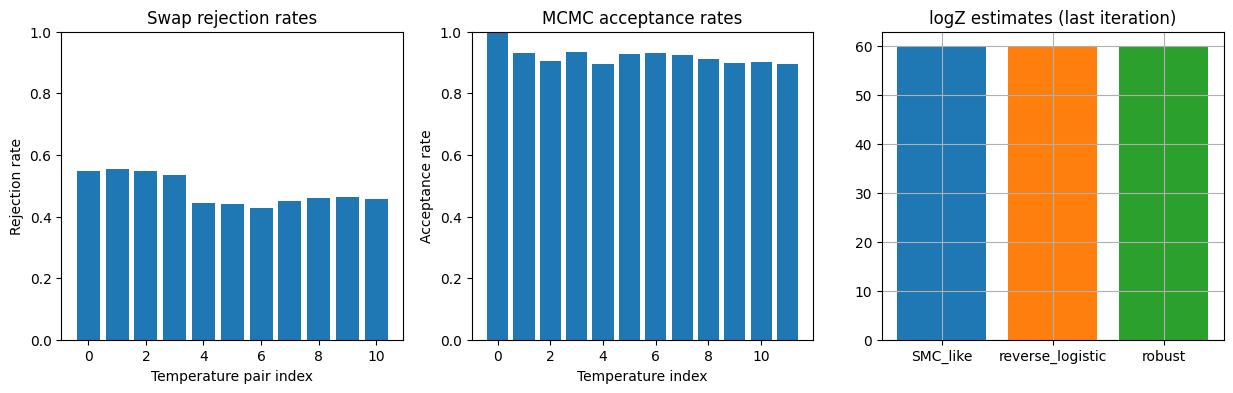

In [18]:
last_diag = diagnostics[-1]

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# Swap rejection rates
axes[0].bar(range(len(temperatures) - 1), last_diag['swap_rejection_rates'])
axes[0].set_xlabel('Temperature pair index')
axes[0].set_ylabel('Rejection rate')
axes[0].set_title('Swap rejection rates')
axes[0].set_ylim(0, 1)

# MCMC acceptance rates
axes[1].bar(range(len(temperatures)), last_diag['mcmc_acc_rates'])
axes[1].set_xlabel('Temperature index')
axes[1].set_ylabel('Acceptance rate')
axes[1].set_title('MCMC acceptance rates')
axes[1].set_ylim(0, 1)

# logZ estimates as bar plot
for name in ['logZ_SMC_like', 'logZ_reverse_logistic', 'logZ_robust']:
    if name in last_diag:
        axes[2].bar(name.replace('logZ_', ''), last_diag[name])
axes[2].set_title('logZ estimates (last iteration)')
axes[2].grid(True)

print("\nlogZ estimates at last iteration:")
for name in ['logZ_SMC_like', 'logZ_reverse_logistic', 'logZ_robust']:
    if name in last_diag:
        print(f"  {name}: {last_diag[name]:.4f}")

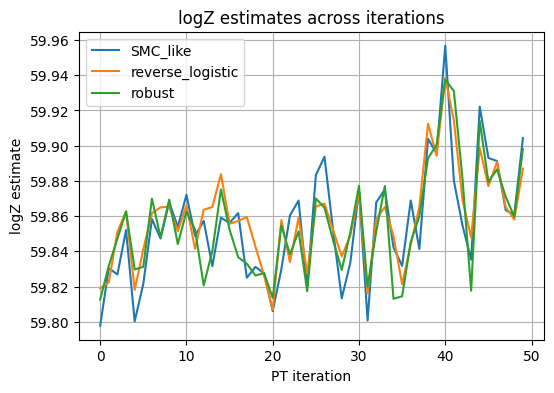

In [19]:
# plot logZ estimates across iterations
fig2, ax2 = plt.subplots(figsize=(6, 4))
for name in ['logZ_SMC_like', 'logZ_reverse_logistic', 'logZ_robust']:
    if name in diagnostics[0]:
        ax2.plot([diag[name] for diag in diagnostics], label=name.replace('logZ_', ''))
ax2.set_title('logZ estimates across iterations')
ax2.set_xlabel('PT iteration')
ax2.set_ylabel('logZ estimate')
ax2.legend()
ax2.grid(True)

## Transforming back to 39D particle positions

The sampler works in the 36D reduced space. To recover physical particle
positions, we apply the inverse map $x_{39D} = Q\, z_{36D}$, then reshape
each 39-vector into 13 particles in 3D.

In [20]:
# Extract particles at the final temperature (t=1)
samples_36d = pt_state.X.position[pt_state.Z[-1]]  # shape (n_particles, 36)

# Map back to 39D and reshape to (n_particles, 13, 3)
samples = samples_36d @ Q.T  # shape (n_particles, 39)
particles = samples.reshape(-1, n_atoms, spatial_dim)  # (n_particles, 13, 3)

# Verify COM is zero
com = particles.mean(axis=1)  # shape (n_particles, 3)
print(f"Max |COM|: {np.max(np.abs(com)):.2e} (should be ~0)")
print(f"Sample shape: {particles.shape} -- (n_particles, 13 atoms, 3D)")

Max |COM|: 2.82e-16 (should be ~0)
Sample shape: (10000, 13, 3) -- (n_particles, 13 atoms, 3D)


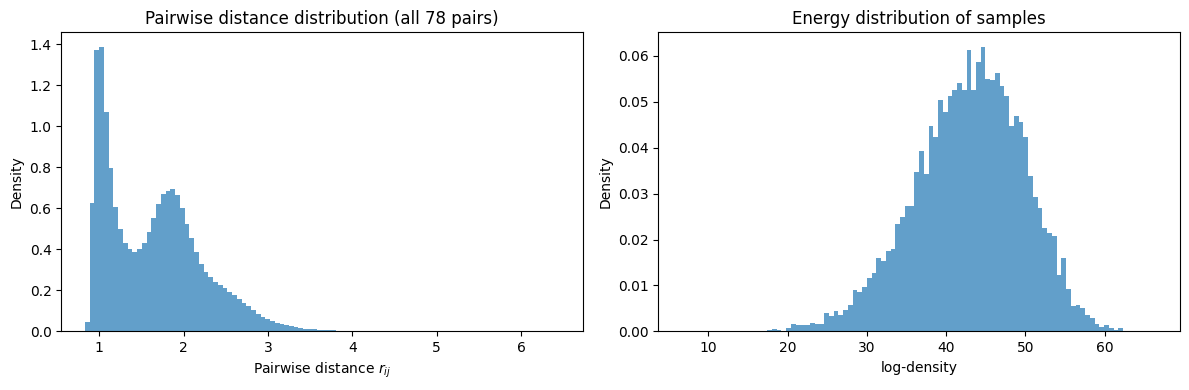

In [21]:
# Compute all pairwise distances for each sample
i_idx, j_idx = np.triu_indices(n_atoms, k=1)  # 78 unique pairs
diffs = particles[:, i_idx] - particles[:, j_idx]  # (n_particles, 78, 3)
distances = np.sqrt(np.sum(diffs**2, axis=-1))     # (n_particles, 78)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Pairwise distance histogram (all 78 pairs pooled)
axes[0].hist(np.array(distances).ravel(), bins=100, density=True, alpha=0.7)
axes[0].set_xlabel('Pairwise distance $r_{ij}$')
axes[0].set_ylabel('Density')
axes[0].set_title('Pairwise distance distribution (all 78 pairs)')

# Energy histogram (using DEM convention with energy_factor=2)
energies = jax.vmap(lj)(np.array(samples))
axes[1].hist(np.array(energies), bins=100, density=True, alpha=0.7)
axes[1].set_xlabel('log-density')
axes[1].set_ylabel('Density')
axes[1].set_title('Energy distribution of samples')

fig.tight_layout()
plt.show()

## Structural analysis

### Cluster radius

The root-mean-square distance from the center of mass measures how
spread out each cluster configuration is:

$$
R_{\text{cluster}} = \sqrt{\frac{1}{N_{\text{atoms}}} \sum_{i=1}^{N_{\text{atoms}}} \|x_i - \bar{x}\|^2}
$$

For the icosahedral LJ13 minimum, this is approximately 1.05.

### Radial distribution function

The radial distribution function $g(r)$ is the histogram of pairwise distances
normalized by the volume of a spherical shell $4\pi r^2 \, dr$.
Peaks in $g(r)$ reveal the shell structure of the cluster: the first peak
corresponds to nearest neighbors, the second to next-nearest neighbors, etc.

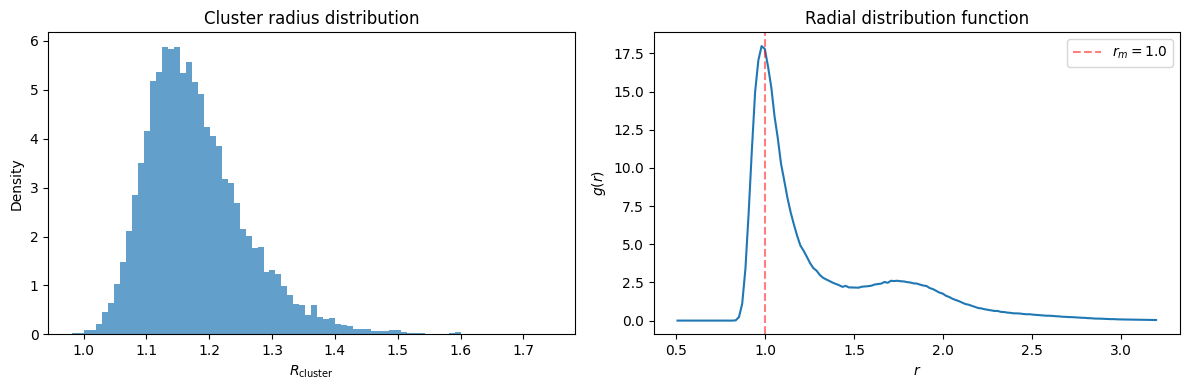

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Cluster radius: RMS distance from center of mass
com = particles.mean(axis=1, keepdims=True)  # (n_particles, 1, 3)
displacements = particles - com               # (n_particles, 13, 3)
r_cluster = np.sqrt(np.mean(np.sum(displacements**2, axis=-1), axis=-1))  # (n_particles,)

axes[0].hist(np.array(r_cluster), bins=80, density=True, alpha=0.7)
axes[0].set_xlabel('$R_{\\mathrm{cluster}}$')
axes[0].set_ylabel('Density')
axes[0].set_title('Cluster radius distribution')

# Radial distribution function g(r)
# Normalize the pairwise distance histogram by the shell volume 4*pi*r^2*dr
r_flat = np.array(distances).ravel()
r_max = float(np.percentile(r_flat, 99))
bins = np.linspace(0.5, r_max, 150)
counts, edges = np.histogram(r_flat, bins=bins, density=False)
r_centers = 0.5 * (edges[:-1] + edges[1:])
dr = edges[1] - edges[0]
shell_volume = 4 * np.pi * r_centers**2 * dr
# Normalize: divide by shell volume and number of samples
n_samples = len(distances)
n_pairs = distances.shape[1]  # 78
g_r = counts / (shell_volume * n_samples * n_pairs / len(bins))

axes[1].plot(r_centers, g_r)
axes[1].set_xlabel('$r$')
axes[1].set_ylabel('$g(r)$')
axes[1].set_title('Radial distribution function')
axes[1].axvline(1.0, color='red', linestyle='--', alpha=0.5, label='$r_m = 1.0$')
axes[1].legend()

fig.tight_layout()
plt.show()

## Comparison with reference samples

We compare our PT samples against the DEM reference test split
(`data/test_split_LJ13-1000.npy`). The reference samples are in full 39D
coordinates and need to be centered (COM removed) before comparison since
our sampler works in the COM=0 subspace.

In [23]:
# Load reference samples
ref_samples = np.load(Path().resolve().parent / "data" / "test_split_LJ13-1000.npy")
print(f"Reference samples: {ref_samples.shape}")

# Center reference samples (remove COM)
ref_particles = ref_samples.reshape(-1, n_atoms, spatial_dim)
ref_com = ref_particles.mean(axis=1, keepdims=True)
ref_particles = ref_particles - ref_com
ref_samples = ref_particles.reshape(-1, n_atoms * spatial_dim)

# Pairwise distances for reference
ref_diffs = ref_particles[:, i_idx] - ref_particles[:, j_idx]
ref_distances = np.sqrt(np.sum(ref_diffs**2, axis=-1))

# Energies for reference (using DEM convention with energy_factor=2)
ref_energies = jax.vmap(lj)(ref_samples)

Reference samples: (10000, 39)


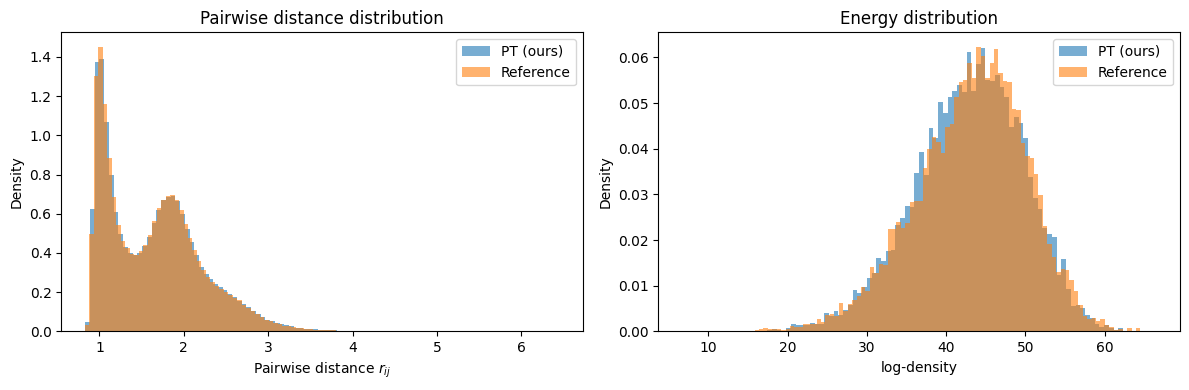

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Pairwise distance comparison
axes[0].hist(np.array(distances).ravel(), bins=100, density=True, alpha=0.6, label='PT (ours)')
axes[0].hist(ref_distances.ravel(), bins=100, density=True, alpha=0.6, label='Reference')
axes[0].set_xlabel('Pairwise distance $r_{ij}$')
axes[0].set_ylabel('Density')
axes[0].set_title('Pairwise distance distribution')
axes[0].legend()

# Energy comparison
axes[1].hist(np.array(energies), bins=100, density=True, alpha=0.6, label='PT (ours)')
axes[1].hist(np.array(ref_energies), bins=100, density=True, alpha=0.6, label='Reference')
axes[1].set_xlabel('log-density')
axes[1].set_ylabel('Density')
axes[1].set_title('Energy distribution')
axes[1].legend()

fig.tight_layout()
plt.show()